# Health Insurance Churn Prediction — Phase 3: Explainable AI (SHAP)
**Goal:** Open up the XGBoost black box — explain WHY each prediction was made, both globally and for individual customers

**Input:** Saved models and data splits from Phase 2 (`xgb_model.pkl`, `X_train.csv`, etc.)  
**Output:** Global feature importance, individual customer explanations, and the key dissertation finding — does SHAP close the interpretability gap?

## Cell 1 — Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import joblib
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (10, 5)

print('Libraries loaded successfully')
print(f'SHAP version: {shap.__version__}')

Libraries loaded successfully
SHAP version: 0.52.0


## Cell 2 — Load saved models and data from Phase 2

No retraining needed — we saved everything at the end of Phase 2 specifically for this step.

In [2]:
xgb_model = joblib.load('xgb_model.pkl')
log_reg   = joblib.load('log_reg_model.pkl')
scaler    = joblib.load('scaler.pkl')

X_train = pd.read_csv('X_train.csv')
X_test  = pd.read_csv('X_test.csv')
y_train = pd.read_csv('y_train.csv').squeeze()
y_test  = pd.read_csv('y_test.csv').squeeze()

print('Loaded successfully:')
print(f'  XGBoost model      : {xgb_model.n_estimators} trees')
print(f'  Logistic Regression: {X_train.shape[1]} coefficients')
print(f'  Test set            : {X_test.shape[0]} customers')

Loaded successfully:
  XGBoost model      : 200 trees
  Logistic Regression: 29 coefficients
  Test set            : 1409 customers


## Cell 3 — Create the SHAP explainer

This is the moment everything in Phase 1 and 2 was building towards.  
`TreeExplainer` is a fast, exact SHAP method built specifically for tree-based models like XGBoost.

In [3]:
# Build the explainer using the trained XGBoost model
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values for every customer in the test set
# This produces one value per customer per feature — how much that feature pushed the prediction
shap_values = explainer.shap_values(X_test)

print(f'SHAP values calculated for {X_test.shape[0]} customers')
print(f'Shape: {shap_values.shape}  (customers x features)')
print(f'\nEach value answers: "how much did this feature push THIS customer\'s prediction up or down?"')

SHAP values calculated for 1409 customers
Shape: (1409, 29)  (customers x features)

Each value answers: "how much did this feature push THIS customer's prediction up or down?"


## Cell 4 — Global feature importance (beeswarm plot)

This is your single most important chart for the dissertation. It shows, across ALL customers,
which features matter most — and whether high or low values of that feature increase churn risk.

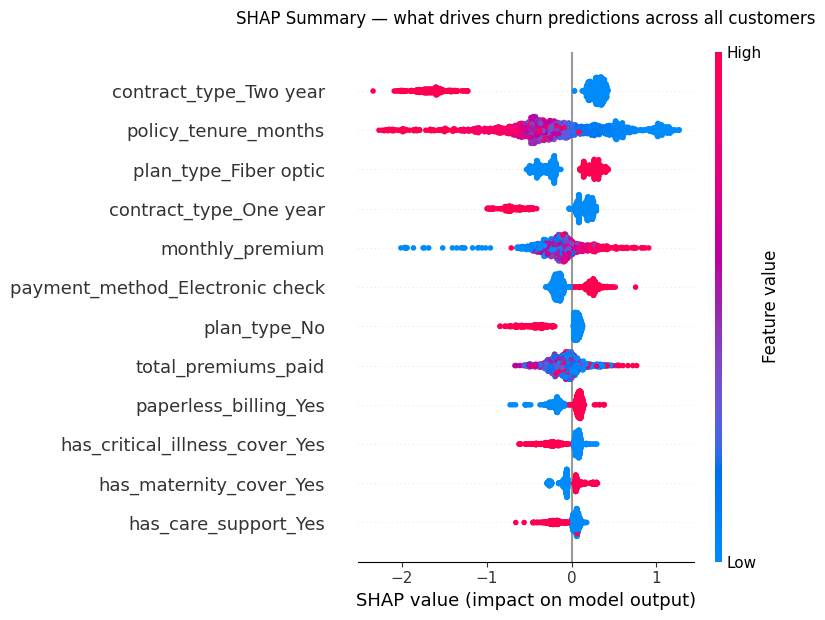

How to read this chart:
  Each dot = one customer
  Position left/right = how much that feature pushed THIS prediction down/up
  Colour = the actual value of that feature (red = high, blue = low)
  Features are ranked top-to-bottom by overall importance


In [4]:
plt.figure()
shap.summary_plot(shap_values, X_test, show=False, max_display=12)
plt.title('SHAP Summary — what drives churn predictions across all customers', pad=20)
plt.tight_layout()
plt.savefig('chart_09_shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

print('How to read this chart:')
print('  Each dot = one customer')
print('  Position left/right = how much that feature pushed THIS prediction down/up')
print('  Colour = the actual value of that feature (red = high, blue = low)')
print('  Features are ranked top-to-bottom by overall importance')

## Cell 5 — Global feature importance (bar chart version)

A simpler version of the same information — easier to read at a glance, good for a slide or summary table.

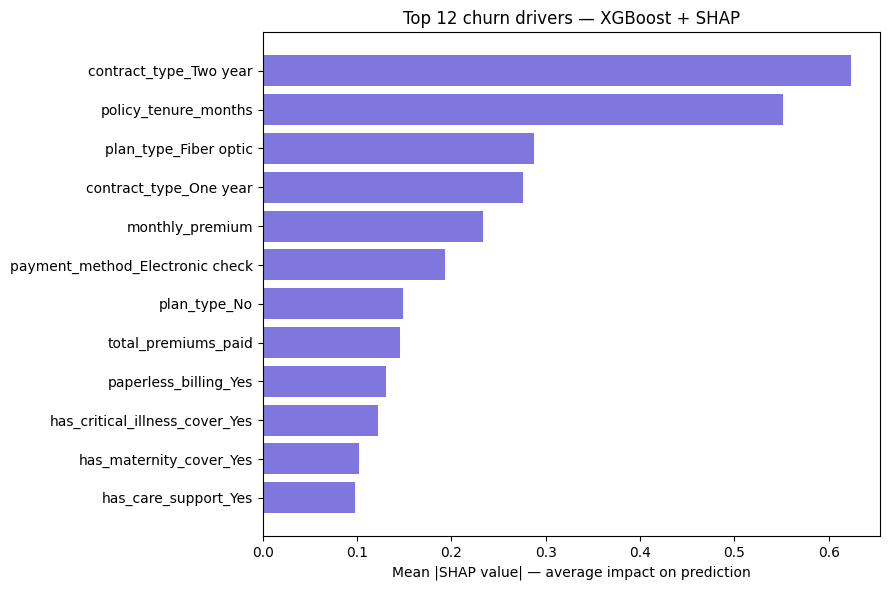

Top 5 churn drivers:
  contract_type_Two year             : 0.6232
  policy_tenure_months               : 0.5510
  plan_type_Fiber optic              : 0.2880
  contract_type_One year             : 0.2762
  monthly_premium                    : 0.2338


In [5]:
# Calculate average absolute SHAP value per feature — this is the "importance score"
mean_abs_shap = np.abs(shap_values).mean(axis=0)
importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance': mean_abs_shap
}).sort_values('importance', ascending=False).head(12)

plt.figure(figsize=(9, 6))
plt.barh(importance_df['feature'][::-1], importance_df['importance'][::-1], color='#7F77DD')
plt.xlabel('Mean |SHAP value| — average impact on prediction')
plt.title('Top 12 churn drivers — XGBoost + SHAP')
plt.tight_layout()
plt.savefig('chart_10_shap_bar_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('Top 5 churn drivers:')
for i, row in importance_df.head(5).iterrows():
    print(f'  {row["feature"]:35s}: {row["importance"]:.4f}')

## Cell 6 — Explain ONE individual customer (waterfall plot)

This is the "local explanation" — for one specific customer, exactly why did the model flag them?
This is what would appear in your D365 dashboard for a retention manager.

Customer index: 1109
Predicted churn probability: 96.7%
Actual outcome: Churned


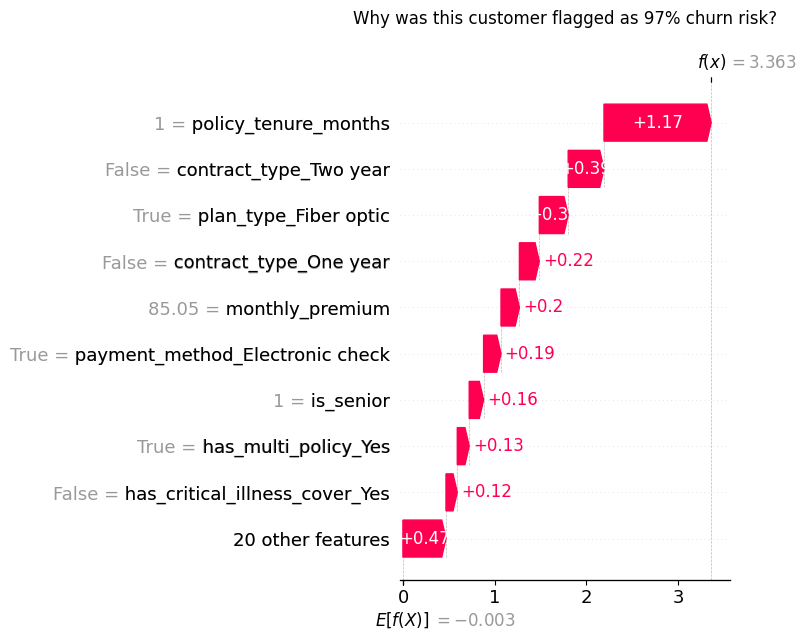


How to read this chart:
  Starts at the average prediction (base value) for all customers
  Each bar shows one feature pushing the prediction UP (red) or DOWN (blue)
  Ends at this customer's final predicted probability
  This is EXACTLY what would appear in the D365 dashboard panel (Phase 4)


In [6]:
# Pick the customer with the HIGHEST predicted churn risk — the most useful case to explain
xgb_proba_test = xgb_model.predict_proba(X_test)[:, 1]
highest_risk_idx = np.argmax(xgb_proba_test)

print(f'Customer index: {highest_risk_idx}')
print(f'Predicted churn probability: {xgb_proba_test[highest_risk_idx]*100:.1f}%')
print(f'Actual outcome: {"Churned" if y_test.iloc[highest_risk_idx] == 1 else "Active"}')

# Build the explanation object SHAP needs for a waterfall plot
explanation = shap.Explanation(
    values=shap_values[highest_risk_idx],
    base_values=explainer.expected_value,
    data=X_test.iloc[highest_risk_idx],
    feature_names=X_test.columns.tolist()
)

plt.figure()
shap.waterfall_plot(explanation, max_display=10, show=False)
plt.title(f'Why was this customer flagged as {xgb_proba_test[highest_risk_idx]*100:.0f}% churn risk?', pad=20)
plt.tight_layout()
plt.savefig('chart_11_shap_waterfall_single_customer.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nHow to read this chart:')
print('  Starts at the average prediction (base value) for all customers')
print('  Each bar shows one feature pushing the prediction UP (red) or DOWN (blue)')
print('  Ends at this customer\'s final predicted probability')
print('  This is EXACTLY what would appear in the D365 dashboard panel (Phase 4)')

## Cell 7 — Compare a high-risk vs low-risk customer side by side

Useful for your dissertation to show the model explains different customers differently — not just one fixed rule.

=== HIGH RISK CUSTOMER ===
Index: 1109 | Predicted risk: 96.7%
Actual outcome: Churned

=== LOW RISK CUSTOMER ===
Index: 1124 | Predicted risk: 0.2%
Actual outcome: Active


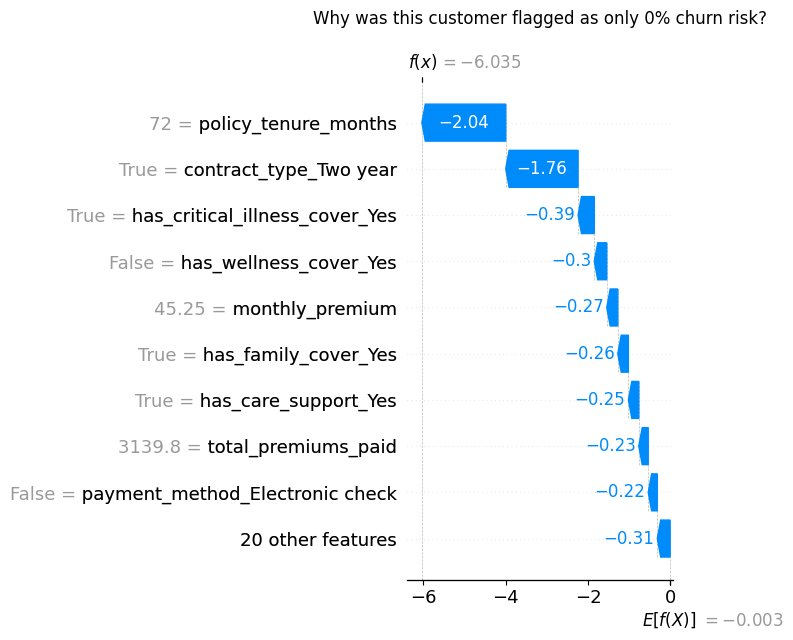

In [7]:
lowest_risk_idx = np.argmin(xgb_proba_test)

print('=== HIGH RISK CUSTOMER ===')
print(f'Index: {highest_risk_idx} | Predicted risk: {xgb_proba_test[highest_risk_idx]*100:.1f}%')
print(f'Actual outcome: {"Churned" if y_test.iloc[highest_risk_idx] == 1 else "Active"}')

print('\n=== LOW RISK CUSTOMER ===')
print(f'Index: {lowest_risk_idx} | Predicted risk: {xgb_proba_test[lowest_risk_idx]*100:.1f}%')
print(f'Actual outcome: {"Churned" if y_test.iloc[lowest_risk_idx] == 1 else "Active"}')

explanation_low = shap.Explanation(
    values=shap_values[lowest_risk_idx],
    base_values=explainer.expected_value,
    data=X_test.iloc[lowest_risk_idx],
    feature_names=X_test.columns.tolist()
)

plt.figure()
shap.waterfall_plot(explanation_low, max_display=10, show=False)
plt.title(f'Why was this customer flagged as only {xgb_proba_test[lowest_risk_idx]*100:.0f}% churn risk?', pad=20)
plt.tight_layout()
plt.savefig('chart_12_shap_waterfall_low_risk.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 8 — Compare SHAP feature importance vs Logistic Regression coefficients

**This is your key research finding.** Does SHAP (explaining the complex XGBoost model) agree with
Logistic Regression's built-in coefficients (which are interpretable by design)?
If they broadly agree, that's strong evidence SHAP successfully recovers interpretability.

In [8]:
# Get Logistic Regression's feature importance (absolute coefficient size)
log_reg_importance = pd.DataFrame({
    'feature': X_train.columns,
    'log_reg_importance': np.abs(log_reg.coef_[0])
})

# Get XGBoost's SHAP-based importance (already calculated in Cell 5)
shap_importance = pd.DataFrame({
    'feature': X_test.columns,
    'shap_importance': mean_abs_shap
})

# Merge and rank both
merged = log_reg_importance.merge(shap_importance, on='feature')
merged['log_reg_rank'] = merged['log_reg_importance'].rank(ascending=False)
merged['shap_rank']    = merged['shap_importance'].rank(ascending=False)
merged['rank_difference'] = abs(merged['log_reg_rank'] - merged['shap_rank'])

# Show top 10 by SHAP importance, with their Logistic Regression rank alongside
top_comparison = merged.sort_values('shap_importance', ascending=False).head(10)
print('=== TOP 10 FEATURES: SHAP RANK vs LOGISTIC REGRESSION RANK ===')
print(top_comparison[['feature', 'shap_rank', 'log_reg_rank', 'rank_difference']].to_string(index=False))

# Calculate overall agreement using Spearman correlation
from scipy.stats import spearmanr
correlation, p_value = spearmanr(merged['log_reg_rank'], merged['shap_rank'])
print(f'\nSpearman rank correlation: {correlation:.3f}')
print(f'(1.0 = perfect agreement, 0 = no relationship, -1.0 = perfect disagreement)')
print(f'\nInterpretation: {"Strong" if correlation > 0.6 else "Moderate" if correlation > 0.3 else "Weak"} agreement between SHAP and Logistic Regression on which features matter most')

=== TOP 10 FEATURES: SHAP RANK vs LOGISTIC REGRESSION RANK ===
                        feature  shap_rank  log_reg_rank  rank_difference
         contract_type_Two year        1.0           4.0              3.0
           policy_tenure_months        2.0           1.0              1.0
          plan_type_Fiber optic        3.0           3.0              0.0
         contract_type_One year        4.0           6.0              2.0
                monthly_premium        5.0           2.0              3.0
payment_method_Electronic check        6.0          10.0              4.0
                   plan_type_No        7.0          17.0             10.0
            total_premiums_paid        8.0           5.0              3.0
          paperless_billing_Yes        9.0          11.0              2.0
 has_critical_illness_cover_Yes       10.0          12.0              2.0

Spearman rank correlation: 0.707
(1.0 = perfect agreement, 0 = no relationship, -1.0 = perfect disagreement)

Interpretati

## Cell 9 — Visualise the agreement

A scatter plot makes the Spearman correlation intuitive — points near the diagonal line mean both methods agree.

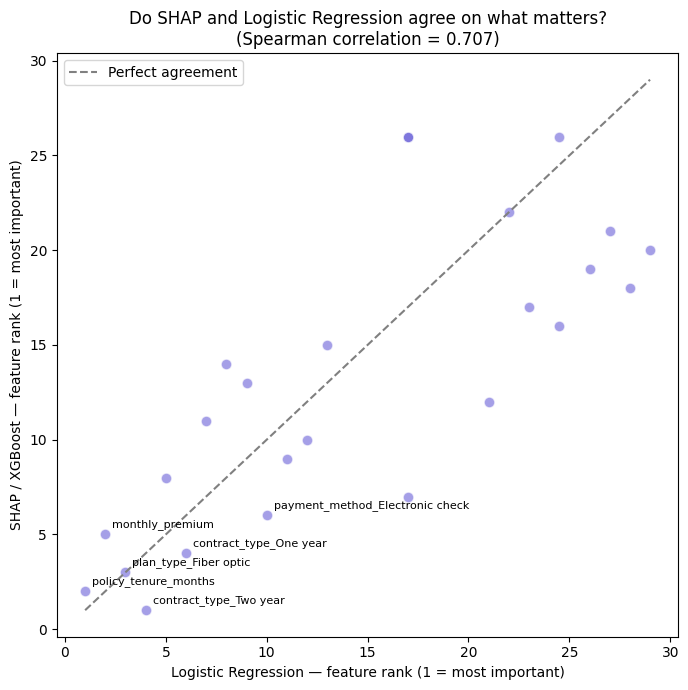

In [9]:
plt.figure(figsize=(7, 7))
plt.scatter(merged['log_reg_rank'], merged['shap_rank'], s=60, color='#7F77DD', alpha=0.7, edgecolors='white')

max_rank = merged['log_reg_rank'].max()
plt.plot([1, max_rank], [1, max_rank], color='gray', linestyle='--', label='Perfect agreement')

# Label the most important features
for _, row in top_comparison.head(6).iterrows():
    plt.annotate(row['feature'], (row['log_reg_rank'], row['shap_rank']),
                fontsize=8, xytext=(5, 5), textcoords='offset points')

plt.xlabel('Logistic Regression — feature rank (1 = most important)')
plt.ylabel('SHAP / XGBoost — feature rank (1 = most important)')
plt.title(f'Do SHAP and Logistic Regression agree on what matters?\n(Spearman correlation = {correlation:.3f})')
plt.legend()
plt.tight_layout()
plt.savefig('chart_13_shap_vs_logreg_agreement.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 10 — Save SHAP outputs for Phase 4 (D365 integration)

Phase 4 needs a function that takes one customer and returns their churn score + top 3 reasons —
exactly what the PCF component will call.

In [10]:
def explain_customer(customer_index, top_n=3):
    """Returns a churn score and the top N reasons for one customer.
    This is the exact logic Phase 4's API endpoint will use."""
    score = xgb_proba_test[customer_index]
    customer_shap = shap_values[customer_index]

    reasons_df = pd.DataFrame({
        'feature': X_test.columns,
        'shap_value': customer_shap
    }).sort_values('shap_value', key=abs, ascending=False).head(top_n)

    return {
        'churn_probability': round(float(score), 3),
        'risk_band': 'High' if score > 0.6 else 'Medium' if score > 0.3 else 'Low',
        'top_reasons': [
            {'feature': row['feature'], 'impact': round(float(row['shap_value']), 3)}
            for _, row in reasons_df.iterrows()
        ]
    }

# Test it on the highest risk customer
result = explain_customer(highest_risk_idx)
print('Example output (this is what the D365 dashboard will receive):')
import json
print(json.dumps(result, indent=2))

# Save the SHAP values and explainer for Phase 4
joblib.dump(explainer, 'shap_explainer.pkl')
np.save('shap_values.npy', shap_values)
print('\nSaved: shap_explainer.pkl, shap_values.npy — ready for Phase 4')

Example output (this is what the D365 dashboard will receive):
{
  "churn_probability": 0.967,
  "risk_band": "High",
  "top_reasons": [
    {
      "feature": "policy_tenure_months",
      "impact": 1.17
    },
    {
      "feature": "contract_type_Two year",
      "impact": 0.391
    },
    {
      "feature": "plan_type_Fiber optic",
      "impact": 0.315
    }
  ]
}

Saved: shap_explainer.pkl, shap_values.npy — ready for Phase 4


## Cell 11 — Phase 3 summary

In [11]:
print('=' * 60)
print('PHASE 3 SUMMARY — EXPLAINABLE AI FINDINGS')
print('=' * 60)
print(f'\nTop 5 churn drivers (by SHAP importance):')
for i, row in importance_df.head(5).iterrows():
    print(f'  {row["feature"]}')

print(f'\nSHAP vs Logistic Regression agreement: {correlation:.3f} (Spearman correlation)')
print(f'\nKEY DISSERTATION FINDING:')
if correlation > 0.6:
    print('  SHAP successfully recovers most of the interpretability that Logistic')
    print('  Regression provides natively — supporting the use of XGBoost + SHAP')
    print('  over a simpler model, despite near-identical raw accuracy.')
else:
    print('  SHAP and Logistic Regression diverge notably on feature importance —')
    print('  suggesting XGBoost captures different patterns than a linear model,')
    print('  which is itself an interesting finding worth discussing.')

print('\nNext step: Phase 4 — Build the PCF component for D365 integration')
print('=' * 60)

PHASE 3 SUMMARY — EXPLAINABLE AI FINDINGS

Top 5 churn drivers (by SHAP importance):
  contract_type_Two year
  policy_tenure_months
  plan_type_Fiber optic
  contract_type_One year
  monthly_premium

SHAP vs Logistic Regression agreement: 0.707 (Spearman correlation)

KEY DISSERTATION FINDING:
  SHAP successfully recovers most of the interpretability that Logistic
  Regression provides natively — supporting the use of XGBoost + SHAP
  over a simpler model, despite near-identical raw accuracy.

Next step: Phase 4 — Build the PCF component for D365 integration
